# Uniform Distribution

Companion notebook for the [uniform distribution note](../../notes/random_variables_and_distributions/continuous/uniform_distribution.md) and its [exercises](../../exercises/random_variables_and_distributions/uniform_distribution.md).

$X\sim\text{Uniform}(a,b)$ has constant density $1/(b-a)$ on $[a,b]$:

$$F(x)=\frac{x-a}{b-a}\ (a\le x\le b),\qquad E[X]=\frac{a+b}2,\qquad \operatorname{Var}(X)=\frac{(b-a)^2}{12}.$$

`scipy.stats.uniform(loc=a, scale=b-a)`.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

rng = np.random.default_rng(42)  # seeded for reproducible simulations

## Hand-rolled implementation

In [2]:
class UniformDistribution:
    def __init__(self, a, b):
        self.a = a
        self.b = b

    def pdf(self, x):
        x = np.asarray(x, dtype=float)
        return np.where((x >= self.a) & (x <= self.b), 1 / (self.b - self.a), 0.0)

    def cdf(self, x):
        x = np.asarray(x, dtype=float)
        return np.clip((x - self.a) / (self.b - self.a), 0.0, 1.0)

## Check against `scipy.stats`

In [3]:
a1, b1 = 0, 5
a2, b2 = 2, 7
x = np.linspace(-1, 8, 1001)
d1, d2 = UniformDistribution(a1, b1), UniformDistribution(a2, b2)

pdf1, pdf2 = stats.uniform.pdf(x, a1, b1 - a1), stats.uniform.pdf(x, a2, b2 - a2)
cdf1, cdf2 = stats.uniform.cdf(x, a1, b1 - a1), stats.uniform.cdf(x, a2, b2 - a2)
print("PDF matches:", np.allclose(d1.pdf(x), pdf1), np.allclose(d2.pdf(x), pdf2))
print("CDF matches:", np.allclose(d1.cdf(x), cdf1), np.allclose(d2.cdf(x), cdf2))

PDF matches: True True
CDF matches: True True


## Shape of the PDF and CDF

The density is a rectangle of height $1/(b-a)$ and the CDF is a ramp from 0 to 1 over $[a,b]$. Both intervals here have length 5, so the PDFs are shifted copies.

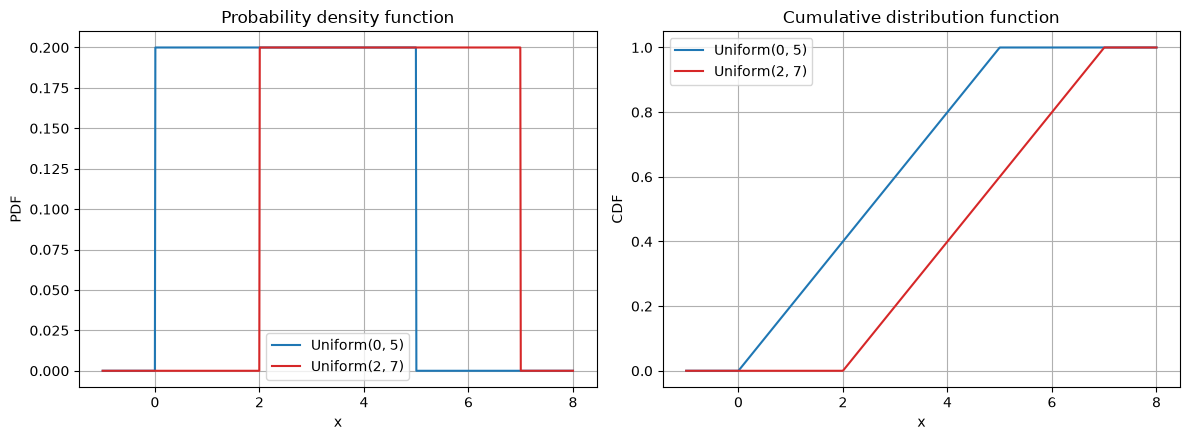

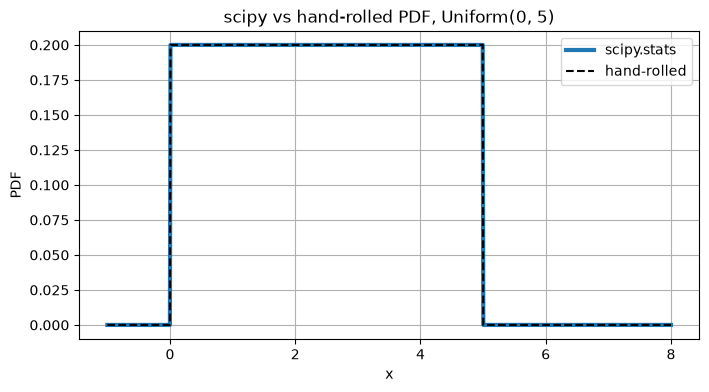

In [4]:
def plot_pdf_cdf(x, pdf1, cdf1, label1, pdf2, cdf2, label2):
    """PDF and CDF of two distributions side by side."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    ax1.plot(x, pdf1, color="C0", label=label1)
    ax1.plot(x, pdf2, color="C3", label=label2)
    ax1.set(xlabel="x", ylabel="PDF", title="Probability density function")
    ax2.plot(x, cdf1, color="C0", label=label1)
    ax2.plot(x, cdf2, color="C3", label=label2)
    ax2.set(xlabel="x", ylabel="CDF", title="Cumulative distribution function")
    for ax in (ax1, ax2):
        ax.legend()
        ax.grid(True)
    plt.tight_layout()
    plt.show()


def plot_overlay(x, ref, custom, title):
    """Hand-rolled PDF (dashed) on top of the scipy.stats PDF (solid)."""
    plt.figure(figsize=(8, 4))
    plt.plot(x, ref, color="C0", linewidth=3, label="scipy.stats")
    plt.plot(x, custom, "k--", label="hand-rolled")
    plt.xlabel("x")
    plt.ylabel("PDF")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


plot_pdf_cdf(x, pdf1, cdf1, f"Uniform({a1}, {b1})", pdf2, cdf2, f"Uniform({a2}, {b2})")
plot_overlay(x, pdf1, d1.pdf(x), "scipy vs hand-rolled PDF, Uniform(0, 5)")

## Worked example: event timing in a game

From the note: the event time is $\text{Uniform}(2,4)$ seconds. Then $P(X<2.5)=0.25$, mean $3$ and variance $1/3$. Conditioning on $X>2.5$ gives a uniform on $(2.5,4)$.

In [5]:
game = UniformDistribution(2, 4)
print(f"P(X < 2.5) = {game.cdf(2.5):.3f}")
print(f"mean = {(2 + 4) / 2}, var = {(4 - 2) ** 2 / 12:.4f}")

# P(X > 3.5 | X > 2.5) = (4 - 3.5) / (4 - 2.5)
cond = (1 - game.cdf(3.5)) / (1 - game.cdf(2.5))
print(f"P(X > 3.5 | X > 2.5) = {cond:.4f}  (= 1/3)")

P(X < 2.5) = 0.250
mean = 3.0, var = 0.3333
P(X > 3.5 | X > 2.5) = 0.3333  (= 1/3)


## Simulation versus theory and the probability integral transform

$F(X)\sim\text{Uniform}(0,1)$ for any continuous $X$. We check this with a normal sample: the histogram of $\Phi(X)$ should be flat.

mean: sample 4.5031  theory 4.5000
var : sample 2.0811  theory 2.0833


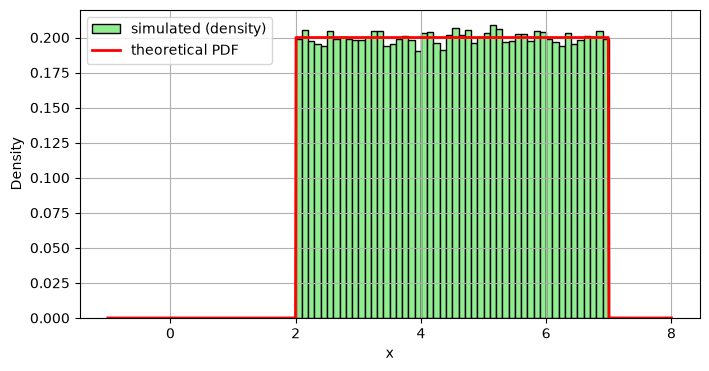

relative frequency of Phi(X) in 10 equal bins: [0.1   0.1   0.1   0.1   0.099 0.1   0.1   0.1   0.099 0.101]


In [6]:
sample = rng.uniform(a2, b2, size=100_000)
print(f"mean: sample {sample.mean():.4f}  theory {(a2 + b2) / 2:.4f}")
print(f"var : sample {sample.var():.4f}  theory {(b2 - a2) ** 2 / 12:.4f}")

plt.figure(figsize=(8, 4))
plt.hist(sample, bins=50, density=True, color="lightgreen", edgecolor="black", label="simulated (density)")
plt.plot(x, stats.uniform.pdf(x, a2, b2 - a2), "r-", linewidth=2, label="theoretical PDF")
plt.xlabel("x")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.show()

# Probability integral transform
u = stats.norm.cdf(rng.normal(size=100_000))
counts, _ = np.histogram(u, bins=10, range=(0, 1))
print("relative frequency of Phi(X) in 10 equal bins:", (counts / u.size).round(3))

## Takeaways

* Uniform probabilities are ratios of lengths: $P(c<X<d)=(d-c)/(b-a)$.
* Conditioning a uniform on a subinterval gives another uniform.
* Uniform draws are the building block of random-number generation (inverse-transform sampling).